In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/train.csv")
print(df.shape)
df.head()

(1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
# 1. What columns do we have, and what types are they?
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [3]:
# 2. Summary statistics for the price we want to predict
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

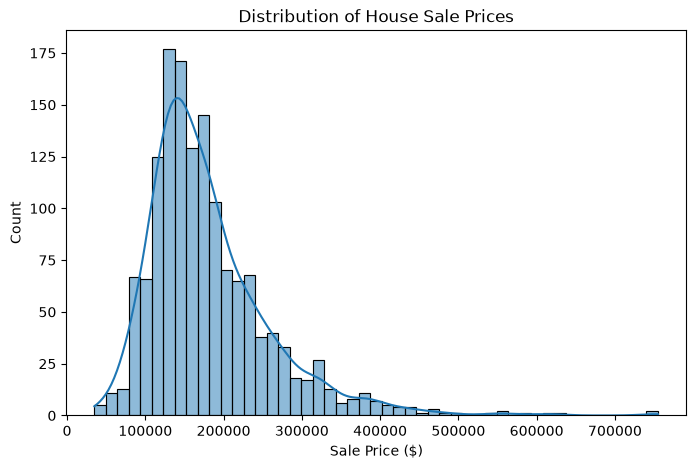

In [4]:
# 3. How are prices distributed?
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price ($)")
plt.show()

Skewness (original): 1.8828757597682118
Skewness (log): 0.12134661989686531


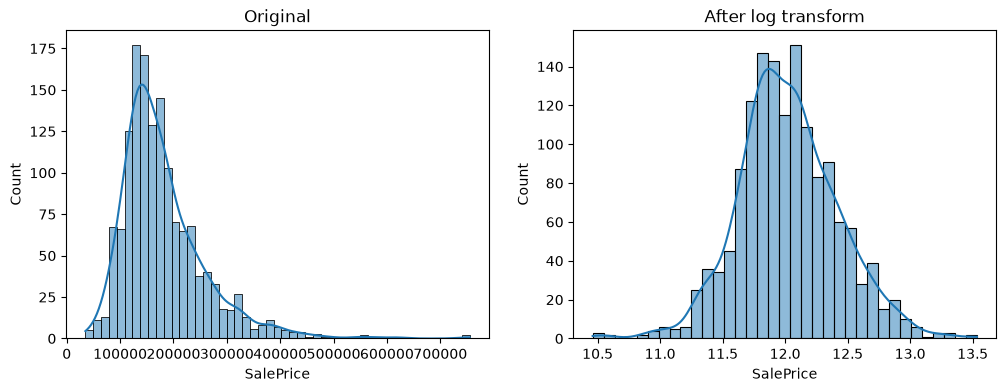

In [5]:
# Skewness before and after log transform
print("Skewness (original):", df["SalePrice"].skew())
print("Skewness (log):", np.log1p(df["SalePrice"]).skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0])
axes[0].set_title("Original")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[1])
axes[1].set_title("After log transform")
plt.show()

In [6]:
# Correlation of numeric columns with SalePrice
corr = df.select_dtypes(include="number").corr()["SalePrice"].sort_values(ascending=False)
print(corr.head(11))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64


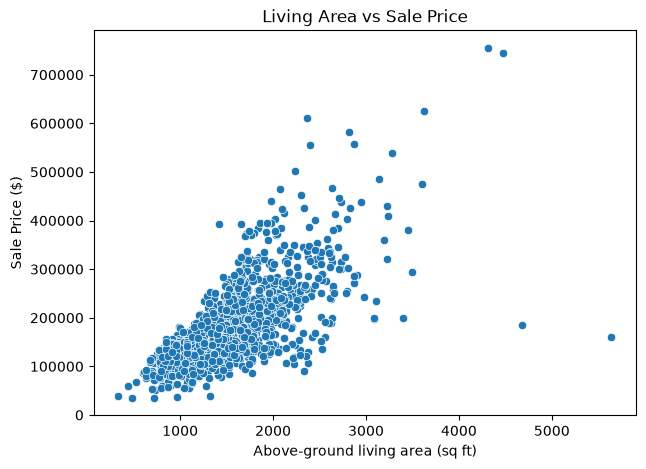

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
plt.title("Living Area vs Sale Price")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.show()

In [8]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [9]:
print("Before:", df.shape)
df = df.drop(df[(df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)].index)
print("After:", df.shape)

Before: (1460, 81)
After: (1458, 81)


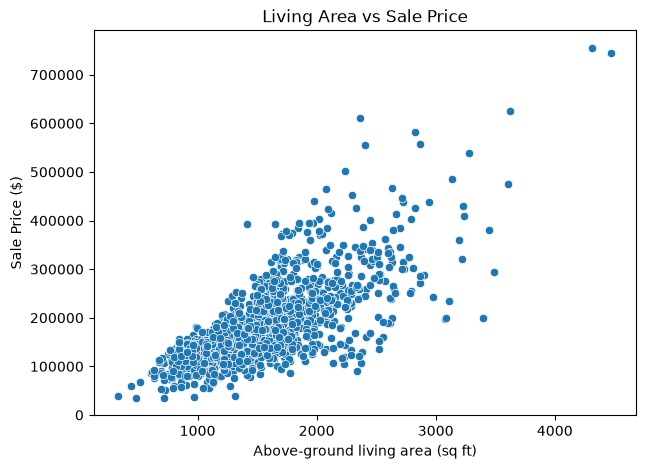

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=df["GrLivArea"], y=df["SalePrice"])
plt.title("Living Area vs Sale Price")
plt.xlabel("Above-ground living area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.show()

In [11]:
# 1. "Missing" really means "this house has no such feature" -> fill with "None"
none_cols = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "MasVnrType",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
]
for col in none_cols:
    df[col] = df[col].fillna("None")

# 2. Numeric columns where missing means zero
for col in ["GarageYrBlt", "MasVnrArea"]:
    df[col] = df[col].fillna(0)

# 3. LotFrontage: use the median of the house's neighborhood
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(
    lambda x: x.fillna(x.median())
)

# 4. Electrical: only one missing, use the most common value
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

# Check: should print 0
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [12]:
# Separate the target (log-transformed) from the features
y = np.log1p(df["SalePrice"])
X = df.drop(columns=["SalePrice", "Id"])

# Convert text columns to numeric columns
X = pd.get_dummies(X, drop_first=True)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1458, 258)
Target shape: (1458,)


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (1166, 258)
Test set: (292, 258)


In [14]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lin_model = LinearRegression()
lin_model.fit(X_train, y_train)

# Predict on the test set
pred_log = lin_model.predict(X_test)

# RMSE on the log scale, and R²
rmse_log = np.sqrt(mean_squared_error(y_test, pred_log))
r2 = r2_score(y_test, pred_log)

# Convert back to dollars to see the error in real money
pred_dollars = np.expm1(pred_log)
actual_dollars = np.expm1(y_test)
avg_error = np.mean(np.abs(pred_dollars - actual_dollars))

print(f"RMSE (log scale): {rmse_log:.4f}")
print(f"R² score: {r2:.4f}")
print(f"Average error: ${avg_error:,.0f}")

RMSE (log scale): 0.1350
R² score: 0.8918
Average error: $15,435


In [15]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200, random_state=42, n_jobs=-1
)
rf_model.fit(X_train, y_train)

rf_pred_log = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred_log))
rf_r2 = r2_score(y_test, rf_pred_log)
rf_avg_error = np.mean(np.abs(np.expm1(rf_pred_log) - np.expm1(y_test)))

print(f"RMSE (log scale): {rf_rmse:.4f}")
print(f"R² score: {rf_r2:.4f}")
print(f"Average error: ${rf_avg_error:,.0f}")

RMSE (log scale): 0.1474
R² score: 0.8712
Average error: $16,728


In [16]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "RMSE (log)": [rmse_log, rf_rmse],
    "R²": [r2, rf_r2],
    "Avg error ($)": [avg_error, rf_avg_error],
}).round(4)
results

,Model,RMSE (log),R²,Avg error ($)
0,Linear Regression,0.1350,0.8918,15434.9358
1,Random Forest,0.1474,0.8712,16727.5912


In [17]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=500, learning_rate=0.05, max_depth=3,
    subsample=0.8, random_state=42
)
gb_model.fit(X_train, y_train)

gb_pred_log = gb_model.predict(X_test)

gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred_log))
gb_r2 = r2_score(y_test, gb_pred_log)
gb_avg_error = np.mean(np.abs(np.expm1(gb_pred_log) - np.expm1(y_test)))

print(f"RMSE (log scale): {gb_rmse:.4f}")
print(f"R² score: {gb_r2:.4f}")
print(f"Average error: ${gb_avg_error:,.0f}")

RMSE (log scale): 0.1227
R² score: 0.9107
Average error: $14,551


In [18]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest", "Gradient Boosting"],
    "RMSE (log)": [rmse_log, rf_rmse, gb_rmse],
    "R²": [r2, rf_r2, gb_r2],
    "Avg error ($)": [avg_error, rf_avg_error, gb_avg_error],
}).round(4)
results

,Model,RMSE (log),R²,Avg error ($)
0,Linear Regression,0.1350,0.8918,15434.9358
1,Random Forest,0.1474,0.8712,16727.5912
2,Gradient Boosting,0.1227,0.9107,14551.4477


In [19]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=500, learning_rate=0.05, max_depth=3,
        subsample=0.8, random_state=42
    ),
}

cv_results = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=kf, scoring="neg_root_mean_squared_error")
    cv_results[name] = -scores
    print(f"{name}: RMSE = {-scores.mean():.4f} (+/- {scores.std():.4f})")

Linear Regression: RMSE = 0.1299 (+/- 0.0145)
Random Forest: RMSE = 0.1398 (+/- 0.0096)
Gradient Boosting: RMSE = 0.1211 (+/- 0.0087)


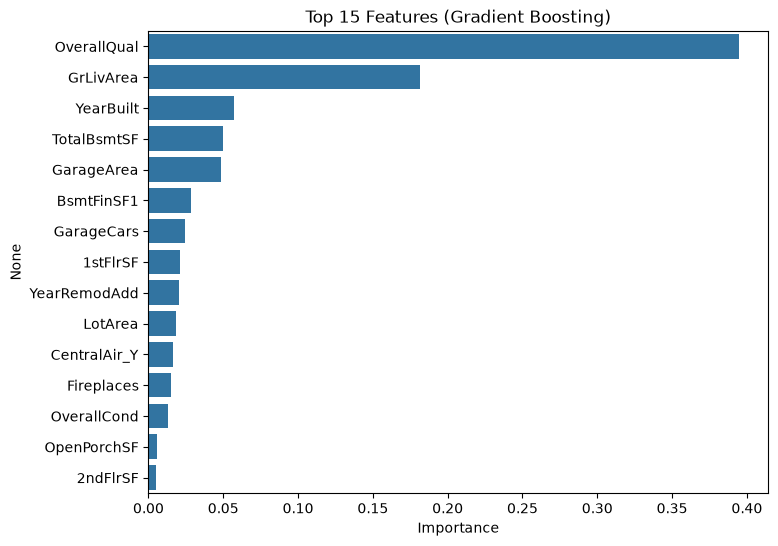

In [20]:
importances = pd.Series(gb_model.feature_importances_, index=X.columns)
top = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top.values, y=top.index)
plt.title("Top 15 Features (Gradient Boosting)")
plt.xlabel("Importance")
plt.show()

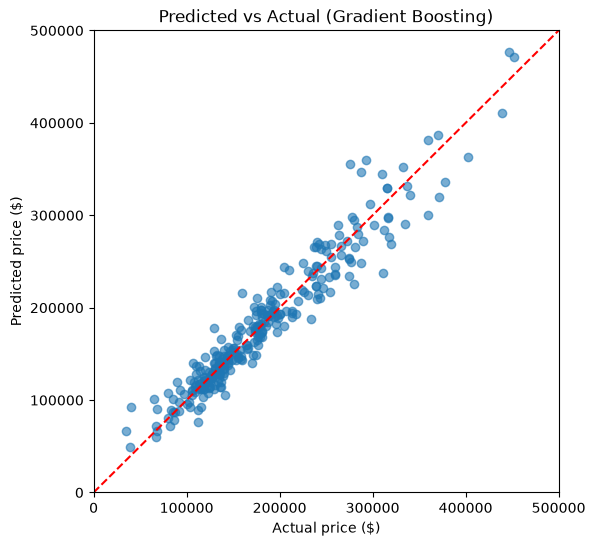

In [21]:
plt.figure(figsize=(6, 6))
plt.scatter(np.expm1(y_test), np.expm1(gb_pred_log), alpha=0.6)
lims = [0, 500000]
plt.plot(lims, lims, "r--")
plt.xlim(lims); plt.ylim(lims)
plt.xlabel("Actual price ($)")
plt.ylabel("Predicted price ($)")
plt.title("Predicted vs Actual (Gradient Boosting)")
plt.show()

In [22]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(gb_model, "../models/gb_model.pkl")
joblib.dump(list(X.columns), "../models/feature_columns.pkl")
print("Saved!")

Saved!


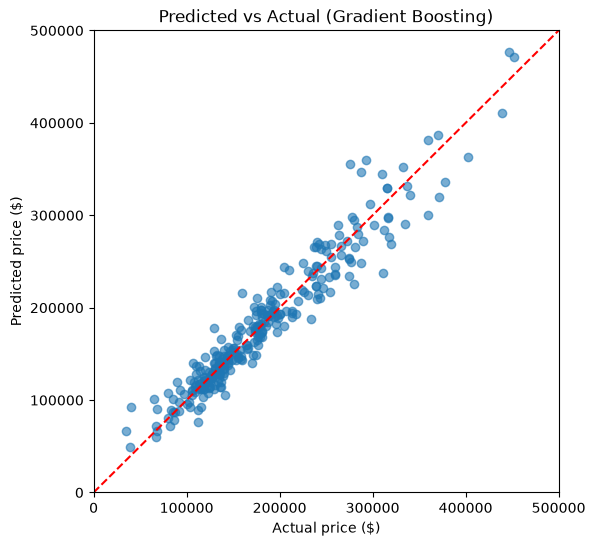

In [24]:
os.makedirs("../images", exist_ok=True)

plt.figure(figsize=(6, 6))
plt.scatter(np.expm1(y_test), np.expm1(gb_pred_log), alpha=0.6)
plt.plot([0, 500000], [0, 500000], "r--")
plt.xlim([0, 500000]); plt.ylim([0, 500000])
plt.xlabel("Actual price ($)"); plt.ylabel("Predicted price ($)")
plt.title("Predicted vs Actual (Gradient Boosting)")
plt.savefig("../images/predicted_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()